# Comparing Daily Temperature Forecasting Across Eight Indian Cities

**NOAA Global Summary of the Day (GSOD), 2010?2024**  
**Target:** daily mean temperature in ?C  
**Locations:** Bengaluru, Delhi, Mumbai, Chennai, Kolkata, Hyderabad, Ahmedabad, and Pune

This notebook brings the city comparison and the remaining forecasting rubric into one reproducible analysis. It uses the saved, out-of-sample analysis artifacts in this repository so that opening and running the notebook does not launch the long model-selection sweep again. The scripts in `src/` are the source of the model fits; their per-city candidate scores and selected orders are loaded below.

## 1. Research question and rubric scope

> How do the temporal patterns and one-step forecast errors of daily mean temperature compare across eight major Indian cities, and which forecasting model families work best under the same evaluation setup?

This is a station-level, observational comparison. The metrics describe these NOAA stations and this test period; they do not establish causal effects or represent every neighbourhood in each city.

The notebook covers the original case-study rubric (research question, data understanding, visualization, trend/seasonality, stationarity, ACF/PACF, and initial findings) and the remaining model-comparison rubric (ARIMA-family selection, Holt-Winters, ML/DL, baselines, accuracy, comparisons, residuals, conclusion, and contribution record).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
while not (ROOT / "src" / "cities.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "cities.py").exists():
    raise FileNotFoundError("Open this notebook from the repository or a subfolder of it.")
sys.path.insert(0, str(ROOT / "src"))
from cities import CITIES

with open(ROOT / "results" / "city_comparison.json", encoding="utf-8") as f:
    base = json.load(f)
with open(ROOT / "results" / "rubric_extension" / "city_model_comparison.json", encoding="utf-8") as f:
    extension = json.load(f)

CITY_NAMES = base["cities"]
base_city = base["per_city_results"]
ext_city = extension["per_city_results"]
print(f"Loaded {len(CITY_NAMES)} cities; test dates: {base_city[CITY_NAMES[0]]['forecast_setup']['test_start']} to {base_city[CITY_NAMES[0]]['forecast_setup']['test_end']}")

Loaded 8 cities; test dates: 2022-10-02 to 2024-12-31


## 2. Dataset and station coverage

Daily temperature comes from NOAA/NCEI GSOD. Each city is represented by one airport or observatory station. GSOD temperature values are converted from ?F to ?C; the cleaned series is placed on a continuous daily calendar, with short temperature gaps interpolated for the time-series models. Precipitation is kept as a secondary descriptive variable and is not a forecast predictor here.

The same dates and temporal split are used for all cities. The final 15% is held out for forecasting; model order selection and fitting use only the earlier 85%.

In [2]:
station_rows = []
for city in CITY_NAMES:
    b = base_city[city]
    station_rows.append({
        "City": city,
        "NOAA station": CITIES[city]["station"],
        "Station name": b.get("station", {}).get("name", ""),
        "Observations": b["dataset"]["n_obs"],
        "Start": b["dataset"]["start"],
        "End": b["dataset"]["end"],
        "Missing raw temperature": b["dataset"]["missing_temperature_c"],
        "Missing precipitation": b["dataset"]["missing_precipitation_mm"],
    })
stations = pd.DataFrame(station_rows)
display(stations)

# One city's descriptive summary as a concrete example; the table above audits all stations.
display(pd.DataFrame.from_dict(base_city["Bengaluru"]["dataset"]["temp_describe"], orient="index", columns=["Bengaluru daily mean temperature (?C)"]))

,City,NOAA station,Station name,Observations,Start,End,Missing raw temperature,Missing precipitation
0,Bengaluru,43295099999,"BANGALORE, IN",5479,2010-01-01,2024-12-31,27,2594
1,Delhi,42182099999,"SAFDARJUNG, IN",5479,2010-01-01,2024-12-31,37,3748
2,Mumbai,43003099999,"CHHATRAPATI SHIVAJI INTERNATIONAL, IN",5479,2010-01-01,2024-12-31,13,3502
3,Chennai,43279099999,"CHENNAI INTERNATIONAL, IN",5479,2010-01-01,2024-12-31,12,3149
4,Kolkata,42809099999,"NETAJI SUBHASH CHANDRA BOSE INTERNATIONAL, IN",5479,2010-01-01,2024-12-31,20,3966
5,Hyderabad,43128099999,"BEGUMPET AIRPORT, IN",5479,2010-01-01,2024-12-31,15,3341
6,Ahmedabad,42647099999,"AHMEDABAD, IN",5479,2010-01-01,2024-12-31,66,4193
7,Pune,43063099999,"PUNE, IN",5479,2010-01-01,2024-12-31,25,3354


,Bengaluru daily mean temperature (?C)
count,5452.000000
mean,24.106750
std,2.228548
min,18.388889
25%,22.500000
50%,23.777778
75%,25.388889
max,31.611111


## 3. Visual comparison of the eight daily series

Aligned panels make differences in seasonal range and short-term variability easier to compare. The station records use the same 2010?2024 window.

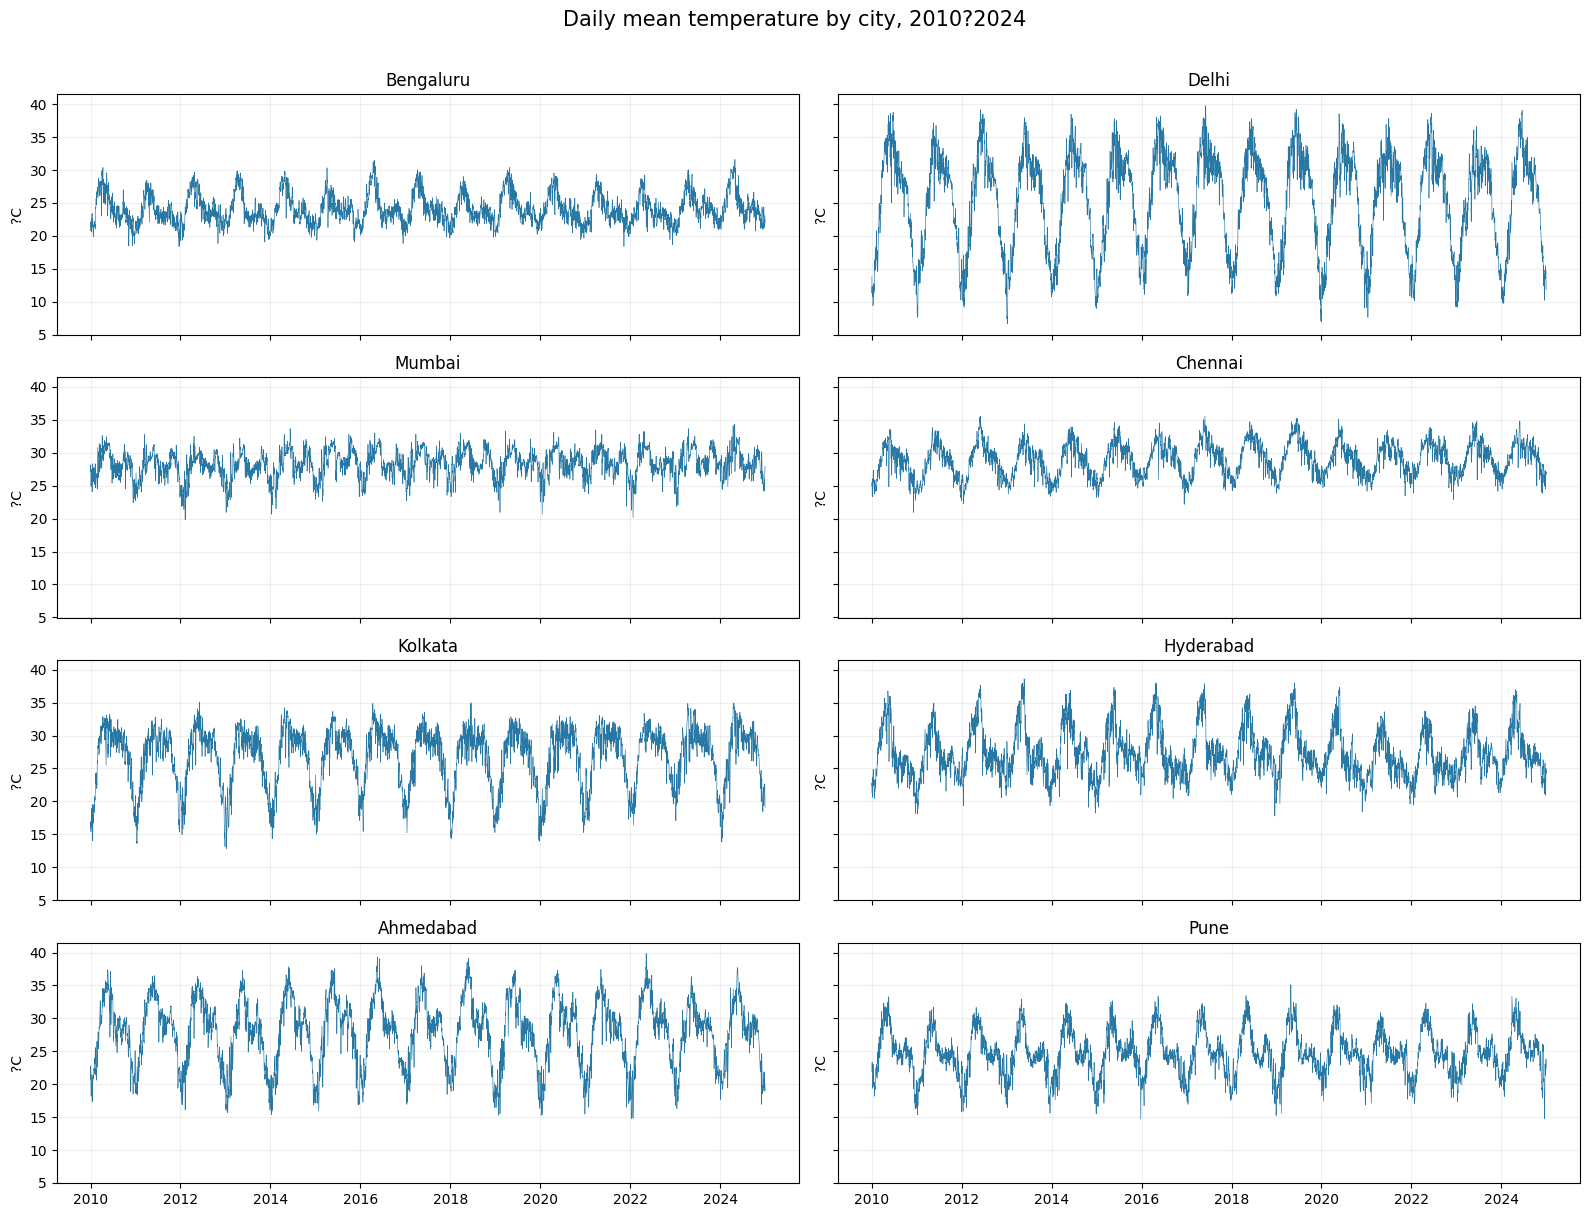

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=True, sharey=True)
for ax, city in zip(axes.flat, CITY_NAMES):
    station = CITIES[city]["station"]
    frame = pd.read_csv(ROOT / "data" / "processed" / f"weather_daily_{station}.csv", parse_dates=["date"])
    ax.plot(frame["date"], frame["temperature_c_interp"], lw=0.45, color="#2878a5")
    ax.set_title(city)
    ax.set_ylabel("?C")
    ax.grid(alpha=0.2)
fig.suptitle("Daily mean temperature by city, 2010?2024", y=1.01, fontsize=15)
fig.tight_layout()
plt.show()

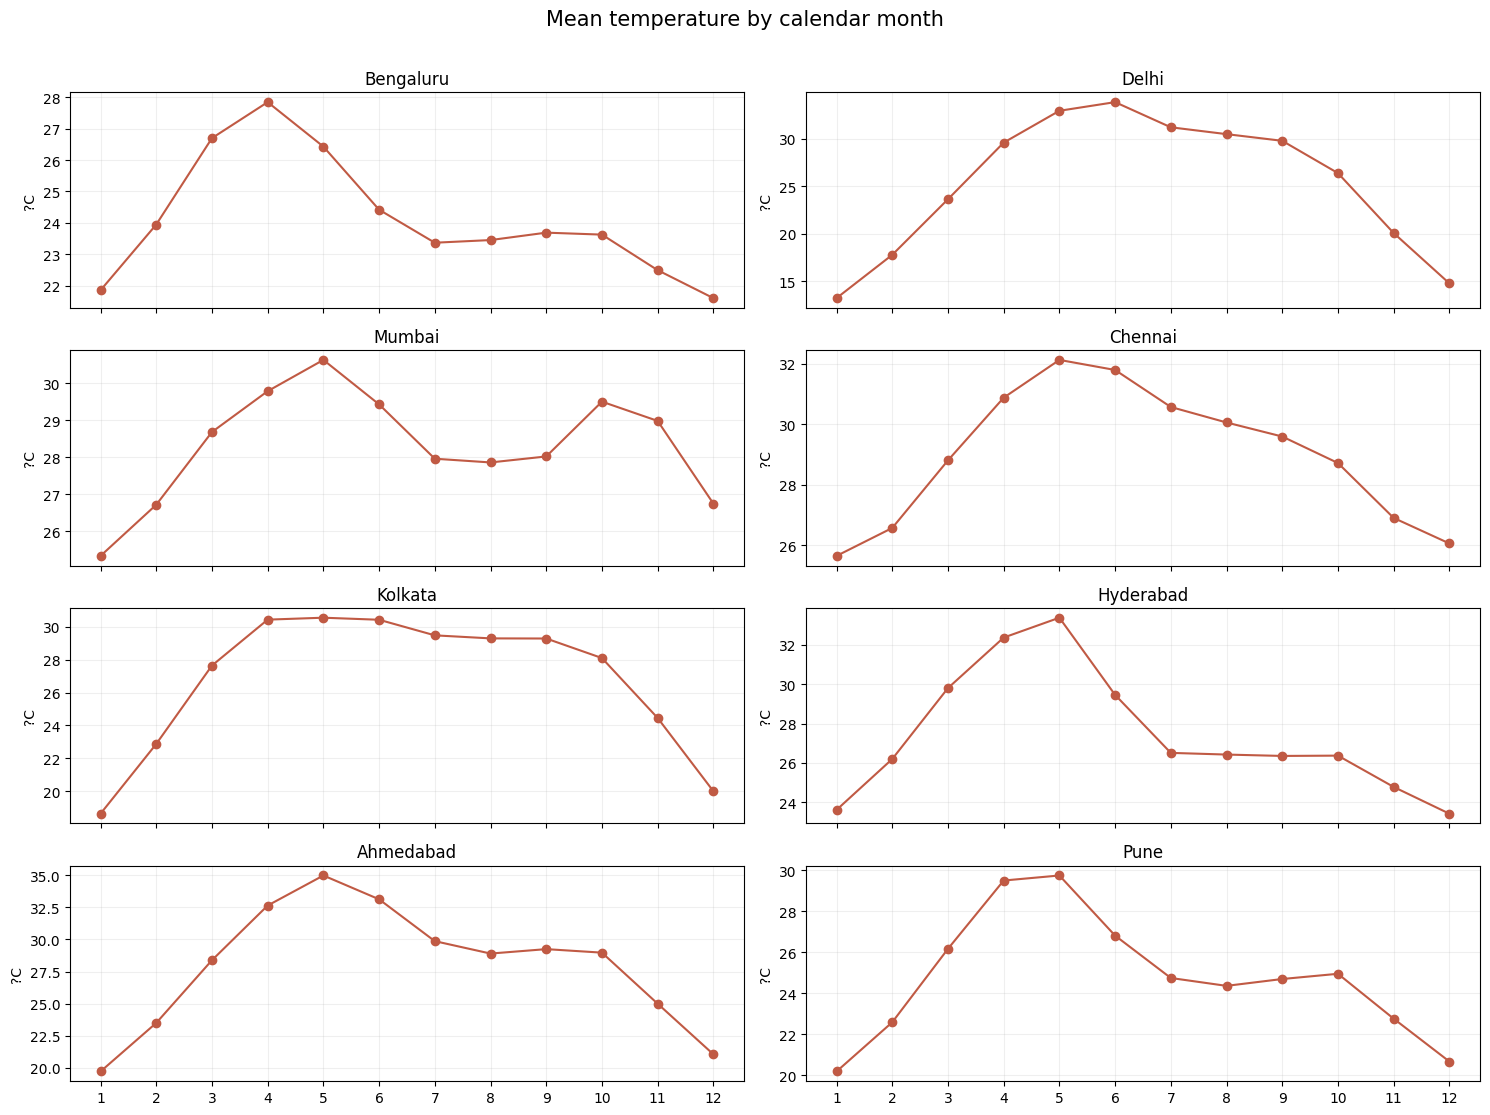

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(15, 11), sharex=True)
for ax, city in zip(axes.flat, CITY_NAMES):
    station = CITIES[city]["station"]
    frame = pd.read_csv(ROOT / "data" / "processed" / f"weather_daily_{station}.csv", parse_dates=["date"])
    frame["month"] = frame["date"].dt.month
    monthly = frame.groupby("month")["temperature_c_interp"].mean()
    ax.plot(monthly.index, monthly.values, marker="o", lw=1.5, color="#c05a44")
    ax.set_title(city)
    ax.set_xticks(range(1, 13))
    ax.set_ylabel("?C")
    ax.grid(alpha=0.2)
fig.suptitle("Mean temperature by calendar month", y=1.01, fontsize=15)
fig.tight_layout()
plt.show()

**Interpretation.** Every location has an annual temperature cycle, but the level, amplitude, and daily variability differ. That makes absolute RMSE useful for comparing forecasting difficulty, while the gain over each city's persistence baseline measures improvement beyond simply using yesterday's temperature.

## 4. Trend, annual seasonality, stationarity, and correlograms

The first-stage city pipeline computed STL trend/seasonal summaries, ADF and KPSS tests, and ACF values. ADF's null is a unit root; KPSS's null is stationarity, so agreement between them is informative because their null hypotheses differ.

In [5]:
pattern_rows = []
stationarity_rows = []
for city in CITY_NAMES:
    b = base_city[city]
    dec, acf = b["decomposition"], b["acf"]
    raw = b["stationarity"]["raw"]
    stationarity_rows.append({
        "City": city,
        "ADF p": raw["adf"]["p_value"],
        "ADF supports stationarity": raw["adf"]["stationary"],
        "KPSS p": raw["kpss"]["p_value"],
        "KPSS supports stationarity": raw["kpss"]["stationary"],
        "Conclusion": raw["conclusion"],
    })
    pattern_rows.append({
        "City": city,
        "Linear trend (?C/decade)": dec["linear_slope_per_decade"],
        "STL trend change (?C)": dec["stl_trend_delta"],
        "Annual seasonal strength": dec["seasonal_strength"],
        "ACF lag 1": acf["lag1_raw"],
        "ACF lag 7": acf["acf_lag7_raw"],
        "ACF lag 365": acf["acf_lag365_raw"],
    })
stationarity_table = pd.DataFrame(stationarity_rows)
pattern_table = pd.DataFrame(pattern_rows)
display(pattern_table.round(3))
display(stationarity_table.round(5))

,City,Linear trend (?C/decade),STL trend change (?C),Annual seasonal strength,ACF lag 1,ACF lag 7,ACF lag 365
0,Bengaluru,0.187,0.304,0.800,0.923,0.768,0.717
1,Delhi,0.056,-0.919,0.933,0.979,0.923,0.909
2,Mumbai,0.581,-0.565,0.636,0.902,0.624,0.577
3,Chennai,0.772,0.939,0.836,0.940,0.807,0.791
4,Kolkata,0.453,-0.106,0.883,0.962,0.859,0.846
5,Hyderabad,-0.398,0.238,0.806,0.940,0.806,0.743
6,Ahmedabad,-0.245,-0.332,0.907,0.973,0.890,0.872
7,Pune,0.186,-0.119,0.851,0.954,0.827,0.802


,City,ADF p,ADF supports stationarity,KPSS p,KPSS supports stationarity,Conclusion
0,Bengaluru,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
1,Delhi,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
2,Mumbai,0.00000,True,0.07564,True,Stationary (ADF & KPSS agree)
3,Chennai,0.00028,True,0.10000,True,Stationary (ADF & KPSS agree)
4,Kolkata,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
5,Hyderabad,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
6,Ahmedabad,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)
7,Pune,0.00000,True,0.10000,True,Stationary (ADF & KPSS agree)


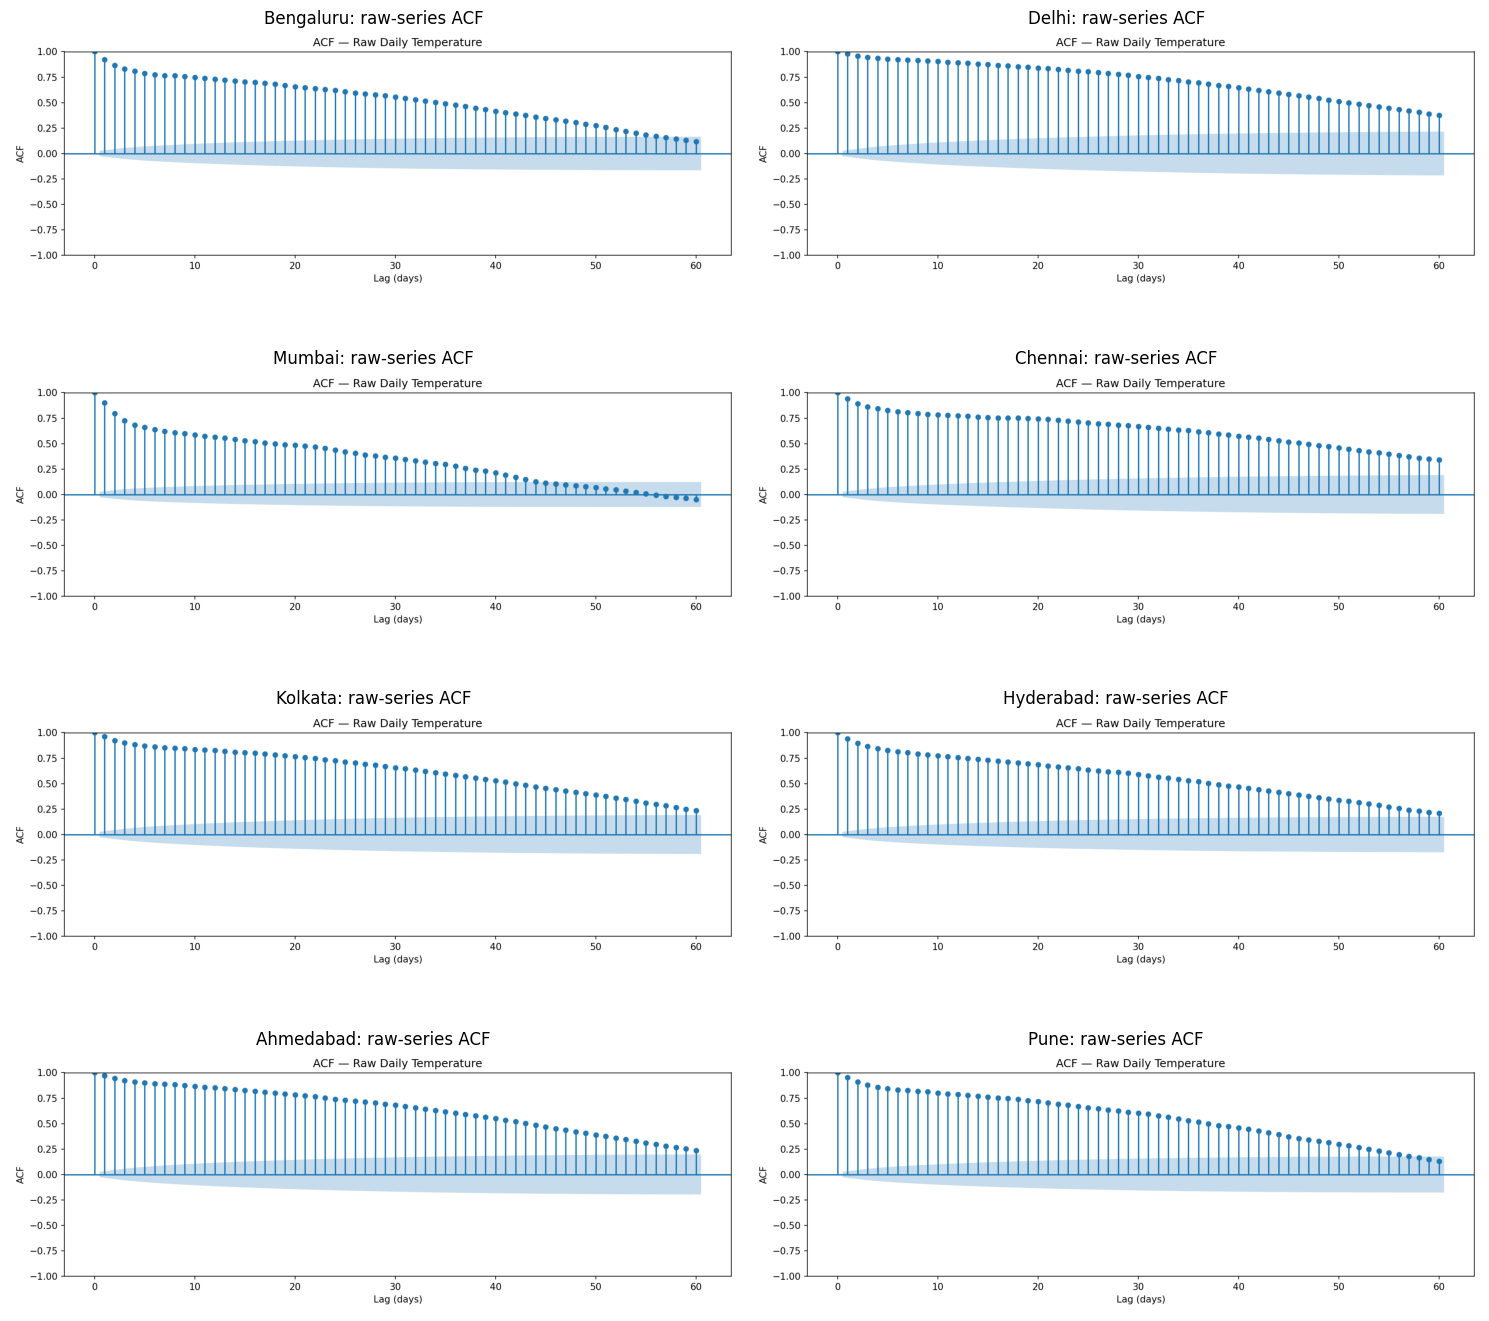

In [6]:
# Example diagnostic figures are already generated for every city by the source pipeline.
from IPython.display import display
fig, axes = plt.subplots(4, 2, figsize=(15, 14))
for ax, city in zip(axes.flat, CITY_NAMES):
    image_path = ROOT / "figures" / "cities" / city.lower() / "acf_raw.png"
    ax.imshow(plt.imread(image_path))
    ax.set_title(f"{city}: raw-series ACF")
    ax.axis("off")
fig.tight_layout()
plt.show()

**Interpretation.** The shared stationarity summaries support level stationarity for these temperature series, while the annual cycle and high short-lag dependence remain clear. The differencing order used in the ARIMA-family fits is selected per city from ADF/KPSS on pre-test data; the selected values and p-values are reported in the order-selection section. Stationarity does not imply that the series has no seasonality.

## 5. Forecast setup and baseline/LSTM/Transformer comparison

The base pipeline uses a chronological 70/15/15 train/validation/test split, a 30-day input window, and a common held-out period. LSTM and Transformer preprocessing is fit on training data only. The one-step results and the direct 1/7/14/21/30-day horizon comparison are loaded from the saved outputs.

In [7]:
one_step_rows = []
horizon_rows = []
for city in CITY_NAMES:
    b = base_city[city]
    summary = next(row for row in base["cities_ranked_by_best_one_step_rmse"] if row["city"] == city)
    one_step_rows.append({
        "City": city,
        "Persistence MAE": summary["persistence_mae"],
        "LSTM MAE": summary["lstm_mae"],
        "Transformer MAE": summary["transformer_mae"],
        "Best one-step model": summary["best_one_step_model"],
        "Best RMSE": summary["best_one_step_rmse"],
        "Transformer skill vs persistence (%)": summary["transformer_skill_vs_persistence_mae_pct"],
    })
    mh = b["multi_horizon"]
    row = {"City": city}
    for model in ("Persistence", "Seasonal naive (365)", "LSTM", "Transformer"):
        row[f"{model} mean-horizon MAE"] = float(np.mean([mh[model][str(h)]["mae"] for h in mh["horizons"]]))
    row["Transformer mean-horizon skill (%)"] = summary["transformer_horizon_skill_pct"]
    horizon_rows.append(row)
base_forecast_table = pd.DataFrame(one_step_rows).sort_values("Best RMSE")
horizon_table = pd.DataFrame(horizon_rows)
display(base_forecast_table.round(3))
display(horizon_table.round(3))

,City,Persistence MAE,LSTM MAE,Transformer MAE,Best one-step model,Best RMSE,Transformer skill vs persistence (%)
0,Bengaluru,0.668,0.650,0.655,"ARIMA(2, 0, 2)",0.829,1.898
2,Mumbai,0.637,0.617,0.637,LSTM,0.858,0.011
3,Chennai,0.649,0.630,0.631,Transformer,0.858,2.741
7,Pune,0.748,0.741,0.743,Transformer,0.976,0.644
6,Ahmedabad,0.778,0.792,0.765,Transformer,1.044,1.652
5,Hyderabad,0.818,0.826,0.818,Transformer,1.090,0.018
4,Kolkata,0.922,0.952,0.956,"ARIMA(2, 0, 2)",1.221,-3.665
1,Delhi,1.051,1.102,1.044,Transformer,1.367,0.662


,City,Persistence mean-horizon MAE,Seasonal naive (365) mean-horizon MAE,LSTM mean-horizon MAE,Transformer mean-horizon MAE,Transformer mean-horizon skill (%)
0,Bengaluru,1.282,1.400,1.179,1.108,13.537
1,Delhi,2.777,2.643,2.313,1.929,30.550
2,Mumbai,1.441,1.543,1.290,1.241,13.886
3,Chennai,1.255,1.213,1.082,1.019,18.778
4,Kolkata,2.160,2.107,1.914,1.721,20.348
5,Hyderabad,1.777,2.019,1.670,1.566,11.847
6,Ahmedabad,2.016,2.039,1.878,1.655,17.893
7,Pune,1.634,1.816,1.506,1.429,12.572


**Onestep Mae**

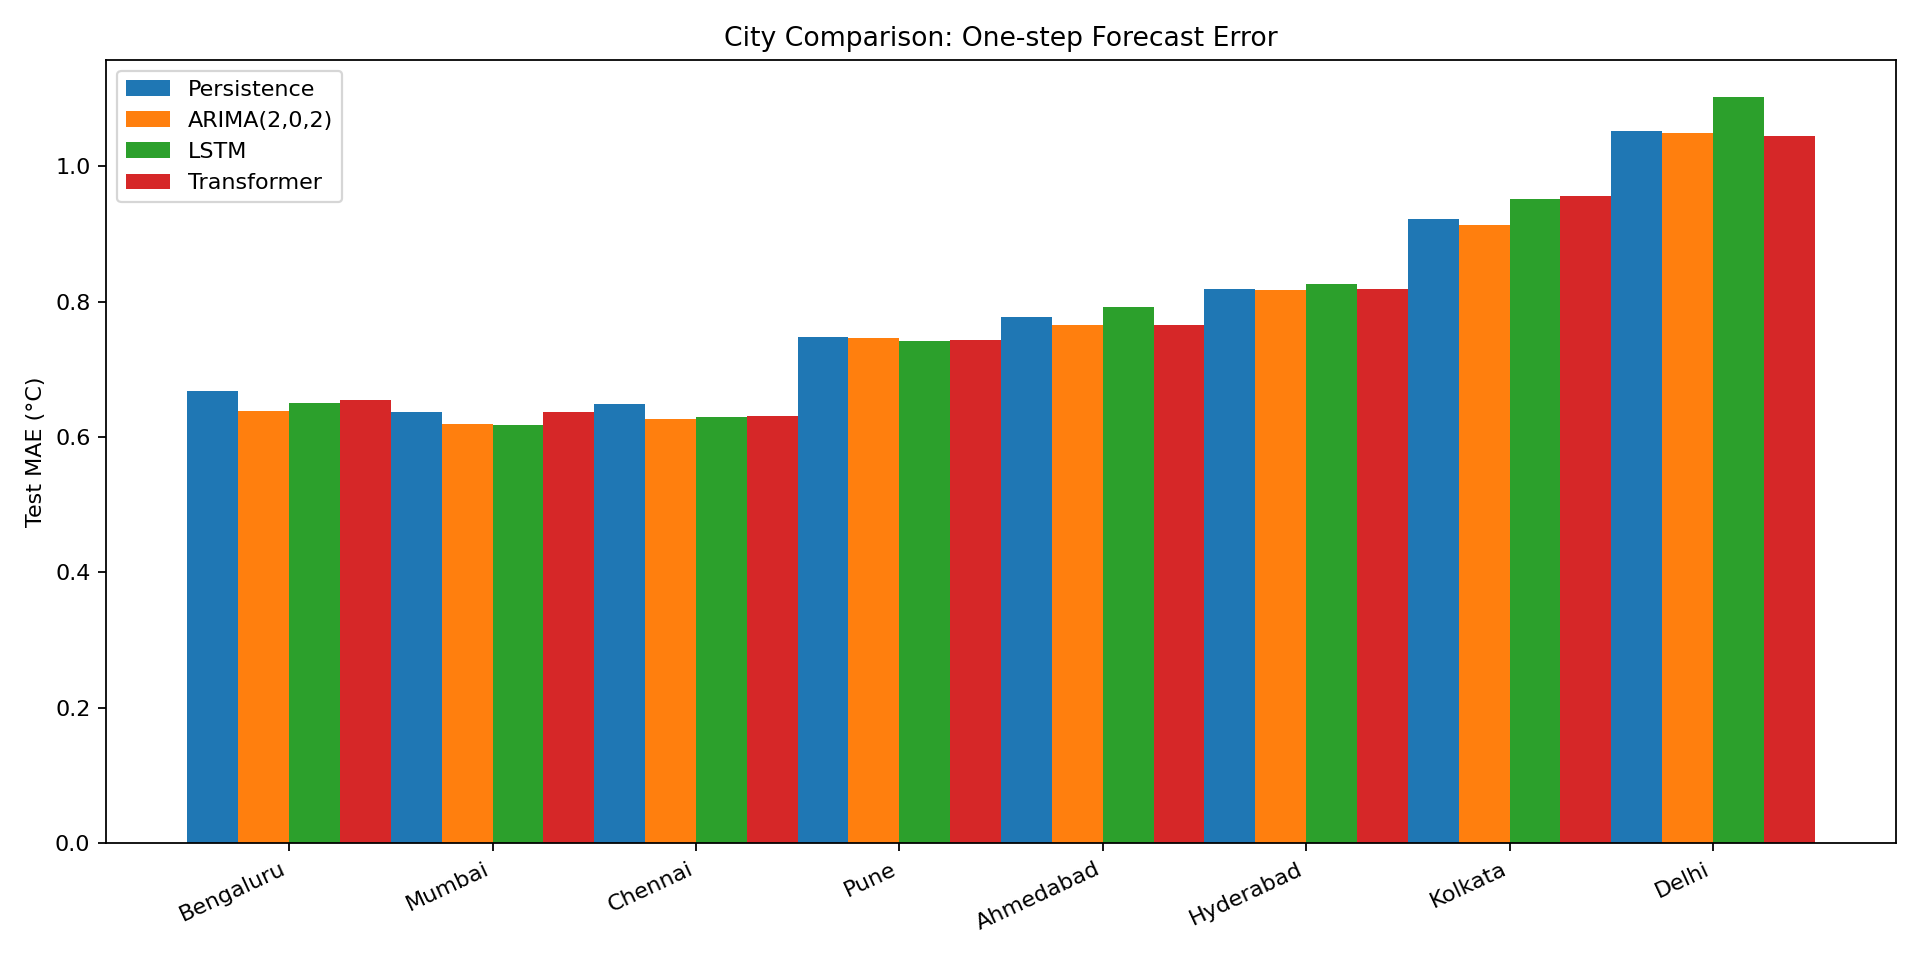

**Transformer Horizon Mae**

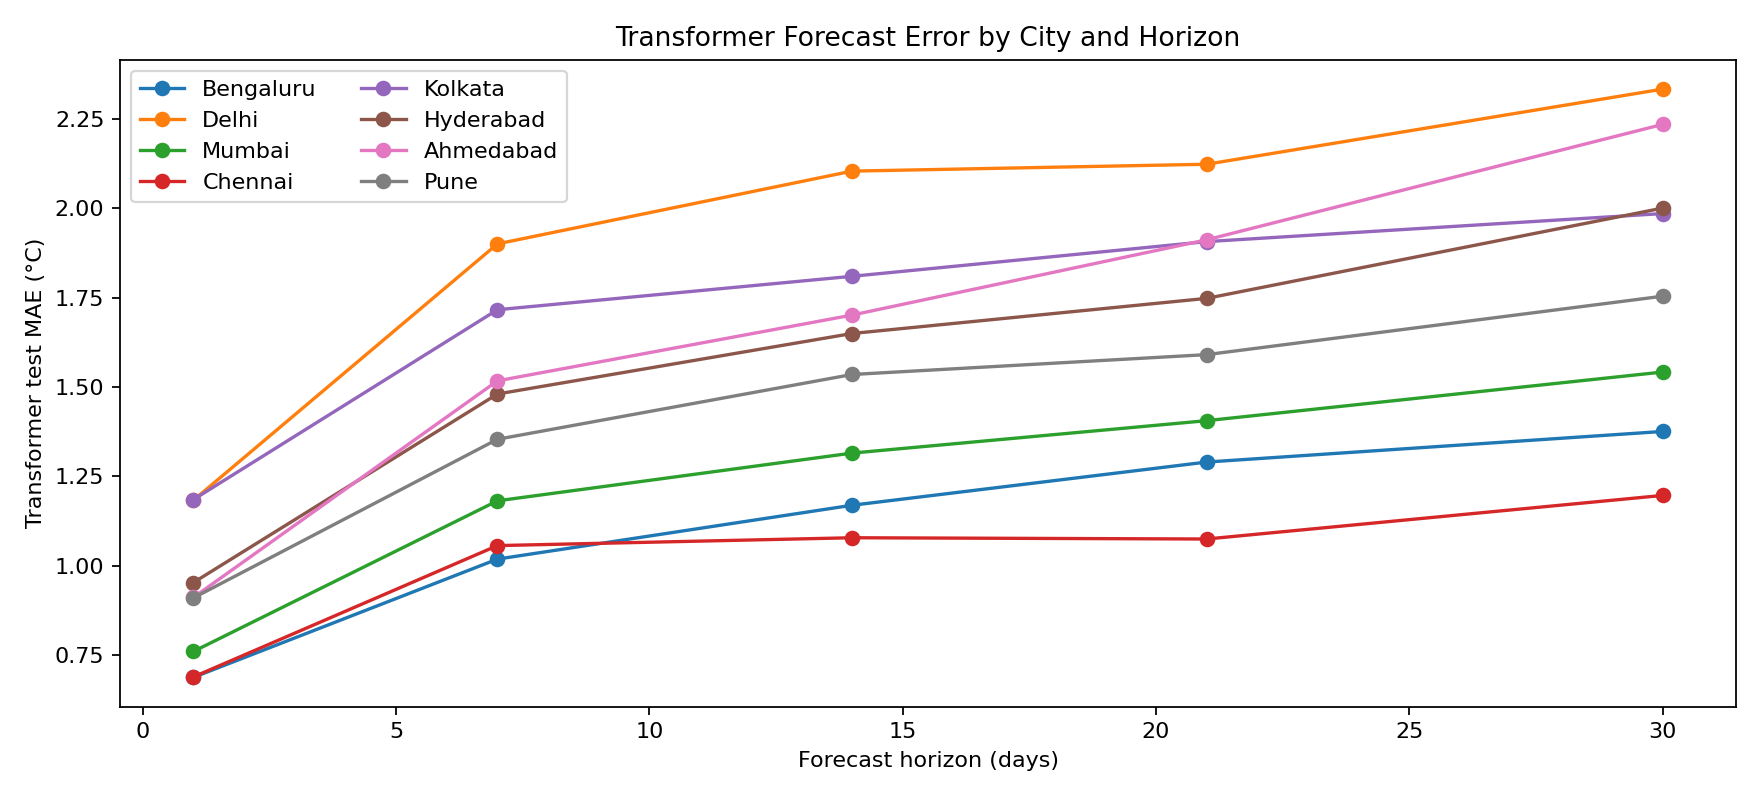

**Skill Vs Persistence**

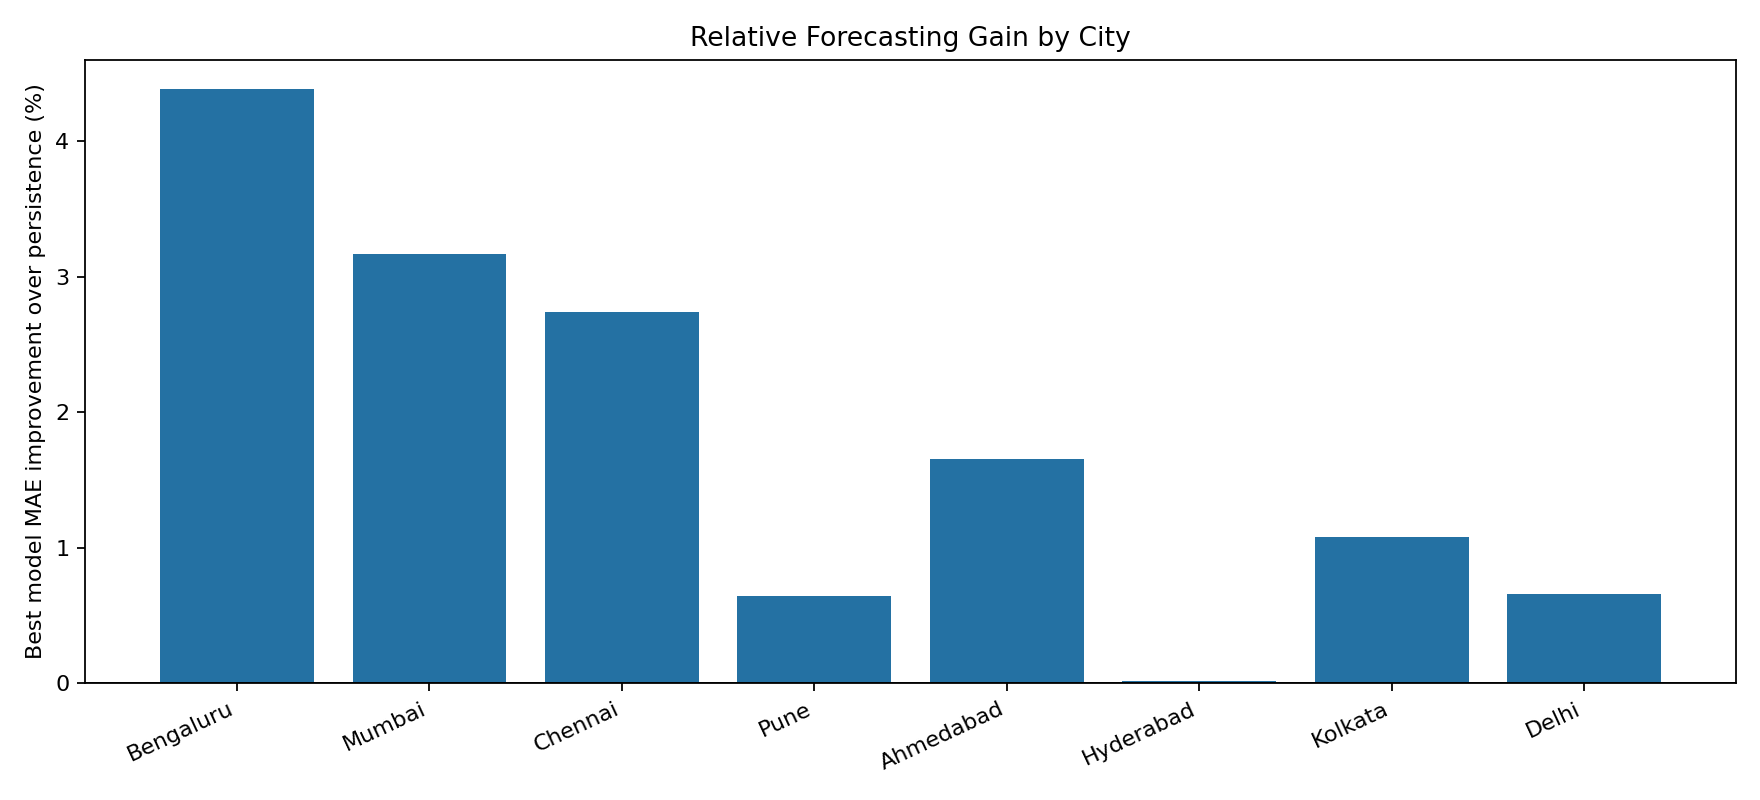

In [8]:
for filename in ("onestep_mae.png", "transformer_horizon_mae.png", "skill_vs_persistence.png"):
    display(Markdown(f"**{filename.replace('_', ' ').replace('.png', '').title()}**"))
    display(Image(filename=str(ROOT / "figures" / "city_comparison" / filename)))

**Baseline interpretation.** Persistence is a strong next-day reference for a highly autocorrelated series. A model can have low absolute error yet add little over persistence, so the notebook reports both city-level error and relative skill.

## 6. ARIMA, SARIMA, ARMAX, and SARIMAX order selection

The earlier fixed ARIMA-family orders were only placeholders; the results below use per-city information-criterion selection.

- **d:** ADF and KPSS are applied to the first 85% of each city's series. The first differencing value for which both tests support stationarity is selected; here we retain the recorded test evidence rather than assume a common d.
- **p and q:** A low-order nonseasonal grid is compared on the pre-test history. Candidate AIC/BIC values and convergence flags are stored for every city and family.
- **P, D, Q, m:** Seasonal models test weekly seasonal AR/MA terms with m = 7 and D = 0. Seasonal variants are tested around the leading nonseasonal p/q candidates ranked by AIC and BIC.
- Both AIC and BIC winners are reported. **BIC-selected orders** supply the one-step forecasts in the main model comparison; the final test period is not used for order selection.
- ARMAX/SARIMAX regressors are deterministic, known-ahead annual and weekly Fourier calendar terms. No future observed weather values are used.

In [9]:
order_rows = []
candidate_rows = []
for city in CITY_NAMES:
    selection = ext_city[city]["information_criterion_order_selection"]
    d = selection["d_selection"]["selected_d"]
    correlogram = selection["d_selection"]["tests"][-1].get("correlogram", {})
    for family in ("ARIMA", "SARIMA", "ARMAX", "SARIMAX"):
        fit = selection[family]
        bic, aic = fit["selected"], fit["selected_by_aic"]
        order_rows.append({
            "City": city, "Selected d": d, "Family": family,
            "BIC order (p,d,q)": tuple(bic["order"]),
            "BIC seasonal (P,D,Q,m)": tuple(bic["seasonal_order"]),
            "BIC": bic["bic"],
            "AIC order (p,d,q)": tuple(aic["order"]),
            "AIC seasonal (P,D,Q,m)": tuple(aic["seasonal_order"]),
            "AIC": aic["aic"],
            "Candidates": fit["candidate_count"],
            "Valid candidates": fit["valid_candidate_count"],
            "ACF q hint": correlogram.get("initial_q_hint"),
            "PACF p hint": correlogram.get("initial_p_hint"),
        })
        for candidate in fit["candidates"]:
            if candidate.get("bic") is not None:
                candidate_rows.append({"City": city, "Family": family, **candidate})
orders = pd.DataFrame(order_rows)
candidates = pd.DataFrame(candidate_rows)
display(orders.round(3))
print(f"Candidate fits with finite AIC/BIC: {len(candidates)}")

,City,Selected d,Family,"BIC order (p,d,q)","BIC seasonal (P,D,Q,m)",BIC,"AIC order (p,d,q)","AIC seasonal (P,D,Q,m)",AIC,Candidates,Valid candidates,ACF q hint,PACF p hint
0,Bengaluru,0,ARIMA,"(1, 0, 2)","(0, 0, 0, 0)",11699.905,"(1, 0, 2)","(0, 0, 0, 0)",11667.678,9,9,3,3
1,Bengaluru,0,SARIMA,"(1, 0, 2)","(0, 0, 1, 7)",11686.675,"(1, 0, 2)","(0, 0, 1, 7)",11648.011,15,15,3,3
2,Bengaluru,0,ARMAX,"(1, 0, 0)","(0, 0, 0, 0)",11392.418,"(1, 0, 0)","(0, 0, 0, 0)",11321.513,9,9,3,3
3,Bengaluru,0,SARIMAX,"(1, 0, 0)","(0, 0, 1, 7)",11383.783,"(1, 0, 1)","(0, 0, 1, 7)",11305.300,15,15,3,3
4,Delhi,0,ARIMA,"(2, 0, 1)","(0, 0, 0, 0)",17008.979,"(2, 0, 1)","(0, 0, 0, 0)",16976.751,9,9,3,3
5,Delhi,0,SARIMA,"(2, 0, 1)","(1, 0, 0, 7)",16991.886,"(2, 0, 1)","(1, 0, 0, 7)",16953.221,15,15,3,3
6,Delhi,0,ARMAX,"(1, 0, 1)","(0, 0, 0, 0)",16673.658,"(1, 0, 1)","(0, 0, 0, 0)",16596.309,9,9,3,3
7,Delhi,0,SARIMAX,"(1, 0, 1)","(0, 0, 1, 7)",16651.997,"(1, 0, 1)","(0, 0, 1, 7)",16568.223,15,15,3,3
8,Mumbai,0,ARIMA,"(1, 0, 2)","(0, 0, 0, 0)",11917.054,"(1, 0, 2)","(0, 0, 0, 0)",11884.826,9,9,3,3
9,Mumbai,0,SARIMA,"(1, 0, 2)","(0, 0, 1, 7)",11901.574,"(1, 0, 2)","(0, 0, 1, 7)",11862.910,18,18,3,3


Candidate fits with finite AIC/BIC: 393


In [10]:
# Inspect the three lowest-BIC candidates for each city/family; all candidates remain in `candidates`.
top_candidates = (candidates.sort_values("bic")
                  .groupby(["City", "Family"], as_index=False, sort=False)
                  .head(3))
display(top_candidates[["City", "Family", "order", "seasonal_order", "aic", "bic", "converged"]].round(2))

,City,Family,order,seasonal_order,aic,bic,converged
195,Chennai,SARIMAX,"[2, 0, 2]","[0, 0, 1, 7]",11124.84,11221.50,True
189,Chennai,SARIMAX,"[1, 0, 0]","[0, 0, 1, 7]",11150.74,11228.07,False
191,Chennai,SARIMAX,"[1, 0, 0]","[1, 0, 1, 7]",11151.23,11235.01,True
179,Chennai,ARMAX,"[2, 0, 2]","[0, 0, 0, 0]",11149.15,11239.39,True
174,Chennai,ARMAX,"[1, 0, 0]","[0, 0, 0, 0]",11175.81,11246.72,True
...,...,...,...,...,...,...,...
65,Delhi,SARIMA,"[2, 0, 2]","[0, 0, 0, 0]",16926.30,16964.97,False
70,Delhi,SARIMA,"[2, 0, 1]","[1, 0, 0, 7]",16953.22,16991.89,True
69,Delhi,SARIMA,"[2, 0, 1]","[0, 0, 1, 7]",16955.09,16993.75,False
55,Delhi,ARIMA,"[2, 0, 1]","[0, 0, 0, 0]",16976.75,17008.98,True


## 7. Remaining model families and accuracy comparison

Holt-Winters models use additive annual seasonality (period 365), with and without a damped trend. Random Forest and Gradient Boosting use lagged temperatures and calendar features. LSTM and Transformer use the base sequence setup. All one-step forecasts are evaluated on the same test dates with MAE, RMSE, MASE, R?, and bias. Lower MAE/RMSE/MASE is better; higher R? is better.

In [11]:
family_summary = pd.DataFrame(extension["models_ranked_by_mean_city_rmse"])
display(family_summary.round(3))

best_rows = []
for city in CITY_NAMES:
    result = ext_city[city]
    for model, metrics in result["model_metrics"].items():
        best_rows.append({"City": city, "Model": model, **metrics})
all_model_scores = pd.DataFrame(best_rows)
display(all_model_scores.sort_values(["City", "rmse"])
        .groupby("City", as_index=False, sort=False).head(3)
        [["City", "Model", "mae", "rmse", "mase", "r2", "bias_actual_minus_predicted"]].round(3))

,model,mean_mae,mean_rmse,mean_mase,mean_r2,cities_won_by_rmse,mean_rmse_rank
0,ARMAX,0.763,1.016,0.935,0.894,2,1.750
1,SARIMAX,0.763,1.016,0.935,0.894,3,2.000
2,RandomForest,0.777,1.027,0.952,0.893,2,3.875
3,GradientBoosting,0.776,1.029,0.949,0.893,1,3.750
4,Transformer,0.781,1.037,0.955,0.890,0,5.875
5,ARIMA,0.774,1.037,0.946,0.890,0,5.750
6,SARIMA,0.775,1.038,0.947,0.890,0,6.375
7,LSTM,0.789,1.051,0.960,0.889,0,6.750
8,Persistence (t-1),0.784,1.071,0.960,0.882,0,8.875
9,Holt-Winters damped,0.859,1.146,1.053,0.865,0,10.125


,City,Model,mae,rmse,mase,r2,bias_actual_minus_predicted
84,Ahmedabad,SARIMAX,0.724,1.015,0.846,0.947,-0.077
85,Ahmedabad,ARMAX,0.726,1.016,0.848,0.947,-0.077
86,Ahmedabad,GradientBoosting,0.761,1.041,0.889,0.944,-0.110
0,Bengaluru,SARIMAX,0.656,0.826,0.982,0.870,0.144
1,Bengaluru,ARMAX,0.656,0.826,0.983,0.870,0.146
2,Bengaluru,LSTM,0.650,0.834,0.973,0.868,0.044
42,Chennai,GradientBoosting,0.621,0.845,1.021,0.863,0.047
43,Chennai,ARMAX,0.628,0.845,1.032,0.862,0.091
44,Chennai,SARIMAX,0.628,0.846,1.032,0.862,0.092
14,Delhi,SARIMAX,1.005,1.338,0.891,0.966,-0.112


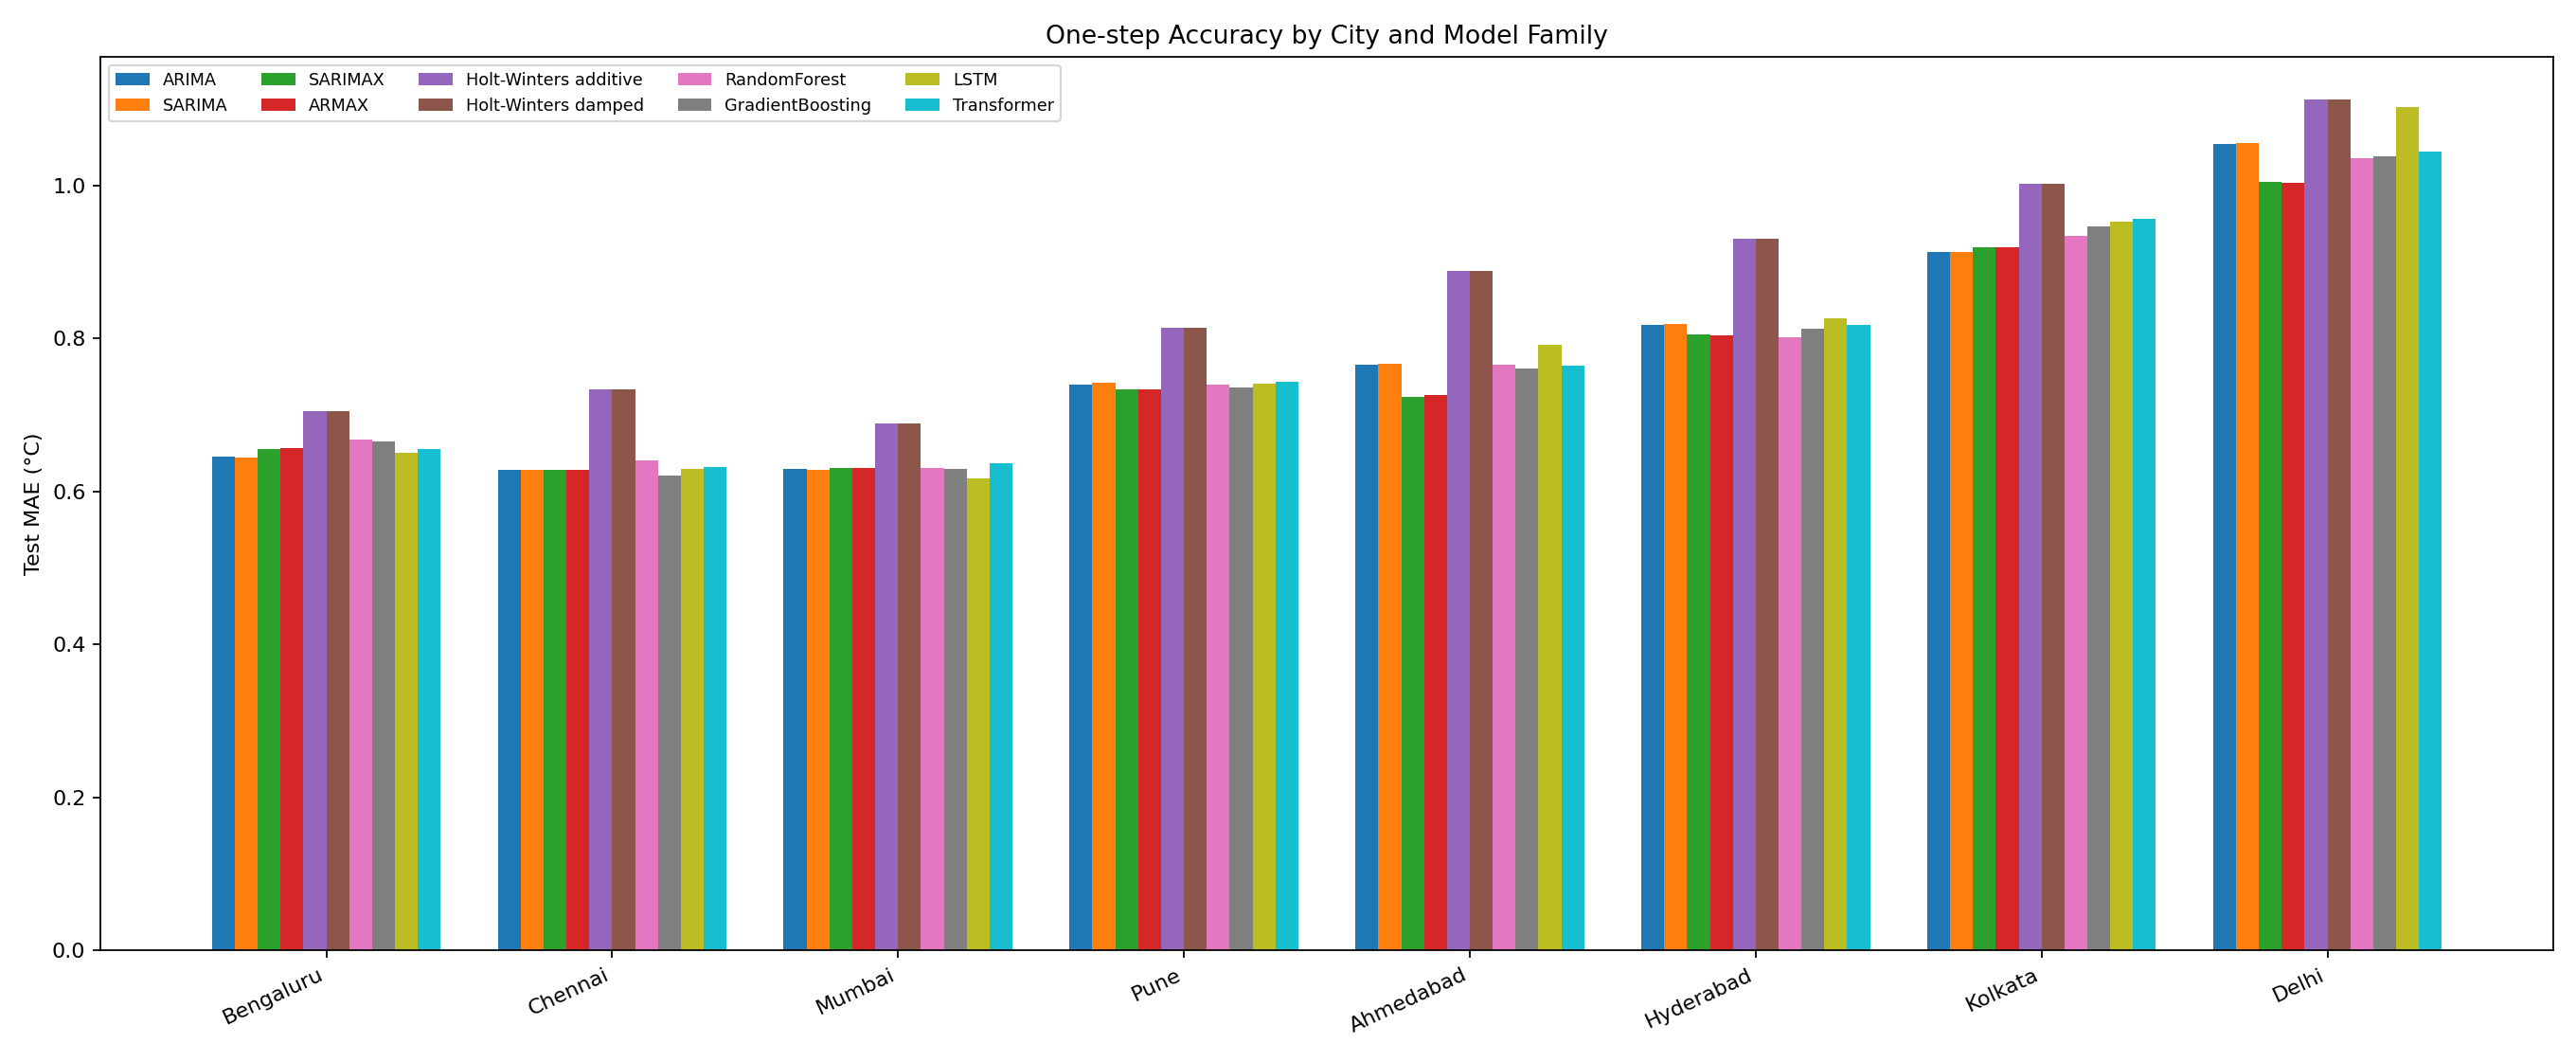

In [12]:
display(Image(filename=str(ROOT / "figures" / "rubric_extension" / "all_models_city_mae.png")))

### Paired model comparison

A paired Diebold?Mariano test compares each model's daily absolute loss with that city's persistence forecast. A Newey?West/HAC variance estimate uses 30 lags, and Holm correction controls the family-wise error across model comparisons within each city. A non-significant result is not proof that two models are equivalent.

In [13]:
dm_rows = []
for city in CITY_NAMES:
    result = ext_city[city]
    best_model = min(result["model_metrics"], key=lambda m: result["model_metrics"][m]["rmse"])
    for model, test in result["diebold_mariano_absolute_loss_vs_persistence"].items():
        dm_rows.append({"City": city, "Model": model,
                        "Mean absolute-loss difference vs persistence": test["mean_abs_loss_difference"],
                        "Holm-adjusted p": test.get("holm_adjusted_p_value"),
                        "Significant at 0.05": test.get("significant_at_0_05"),
                        "Selected best model": model == best_model})
dm_table = pd.DataFrame(dm_rows)
display(dm_table[dm_table["Selected best model"]].round(4))

,City,Model,Mean absolute-loss difference vs persistence,Holm-adjusted p,Significant at 0.05,Selected best model
6,Bengaluru,SARIMAX,-0.0117,1.0000,False,True
19,Delhi,SARIMAX,-0.0468,0.0062,True,True
35,Mumbai,RandomForest,-0.0064,1.0000,False,True
49,Chennai,GradientBoosting,-0.0285,0.0107,True,True
57,Kolkata,ARMAX,-0.0030,1.0000,False,True
74,Hyderabad,RandomForest,-0.0163,1.0000,False,True
84,Ahmedabad,SARIMAX,-0.0537,0.0001,True,True
96,Pune,ARMAX,-0.0145,1.0000,False,True


## 8. Residual analysis

Residuals are actual minus forecast. The table includes mean bias, Durbin?Watson, Ljung?Box at lag 30, and Jarque?Bera. Significant Ljung?Box results suggest remaining serial dependence; significant Jarque?Bera results reject normality. These checks matter when interpreting model assumptions and prediction intervals.

In [14]:
residual_rows = []
for city in CITY_NAMES:
    result = ext_city[city]
    best_model = min(result["model_metrics"], key=lambda m: result["model_metrics"][m]["rmse"])
    diag = result["residual_diagnostics"][best_model]
    residual_rows.append({"City": city, "Selected model": best_model,
                          "Residual mean (?C)": diag["mean"],
                          "Residual SD (?C)": diag["std"],
                          "Durbin-Watson": diag["durbin_watson"],
                          "Ljung-Box lag-30 p": diag["ljung_box_lag30_p"],
                          "Jarque-Bera p": diag["jarque_bera_p"]})
residual_table = pd.DataFrame(residual_rows)
display(residual_table.round(4))

,City,Selected model,Residual mean (?C),Residual SD (?C),Durbin-Watson,Ljung-Box lag-30 p,Jarque-Bera p
0,Bengaluru,SARIMAX,0.1440,0.8136,1.9411,0.0201,0.0
1,Delhi,SARIMAX,-0.1121,1.3339,1.9271,0.0481,0.0
2,Mumbai,RandomForest,0.0689,0.8481,1.6611,0.0052,0.0
3,Chennai,GradientBoosting,0.0469,0.8442,1.9004,0.0507,0.0
4,Kolkata,ARMAX,0.2052,1.1915,1.7416,0.0797,0.0
5,Hyderabad,RandomForest,0.0153,1.0653,1.7894,0.0368,0.0
6,Ahmedabad,SARIMAX,-0.0772,1.0124,1.8859,0.3010,0.0
7,Pune,ARMAX,0.0589,0.9619,1.9327,0.0061,0.0


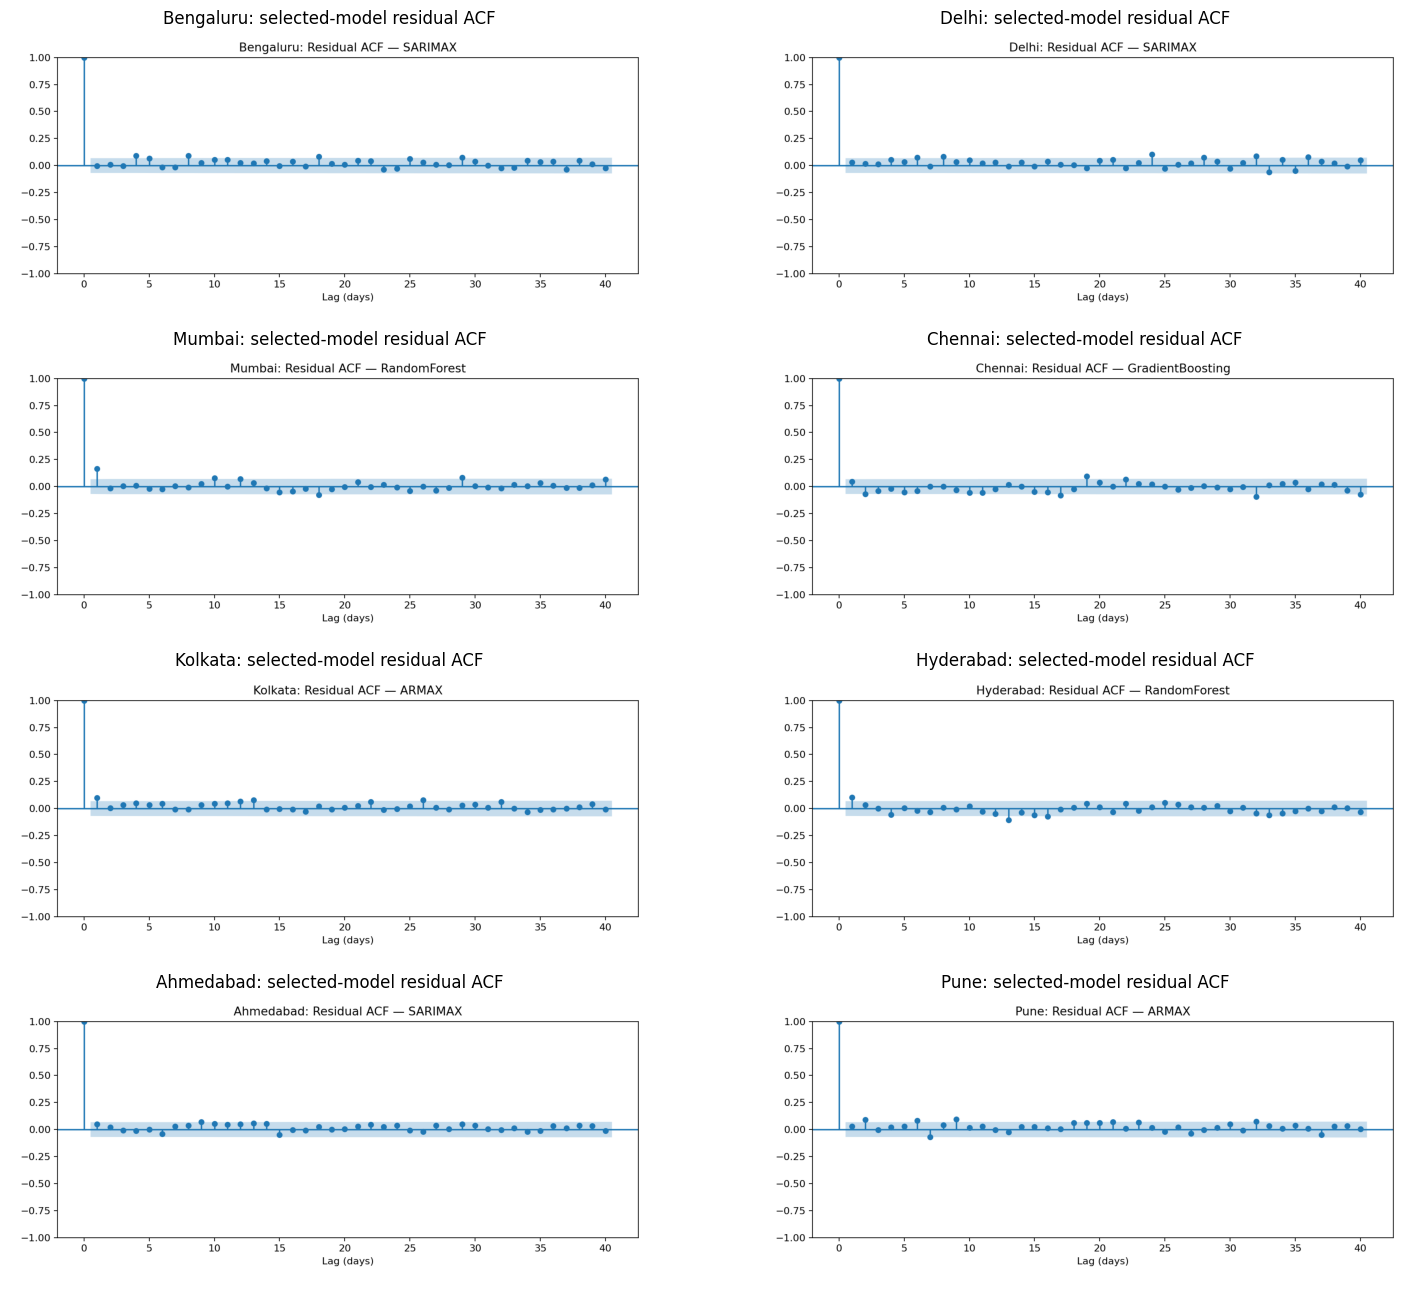

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(16, 13))
for ax, city in zip(axes.flat, CITY_NAMES):
    path = ROOT / "figures" / "rubric_extension" / city.lower() / "best_model_residual_acf.png"
    ax.imshow(plt.imread(path))
    ax.set_title(f"{city}: selected-model residual ACF")
    ax.axis("off")
fig.tight_layout()
plt.show()

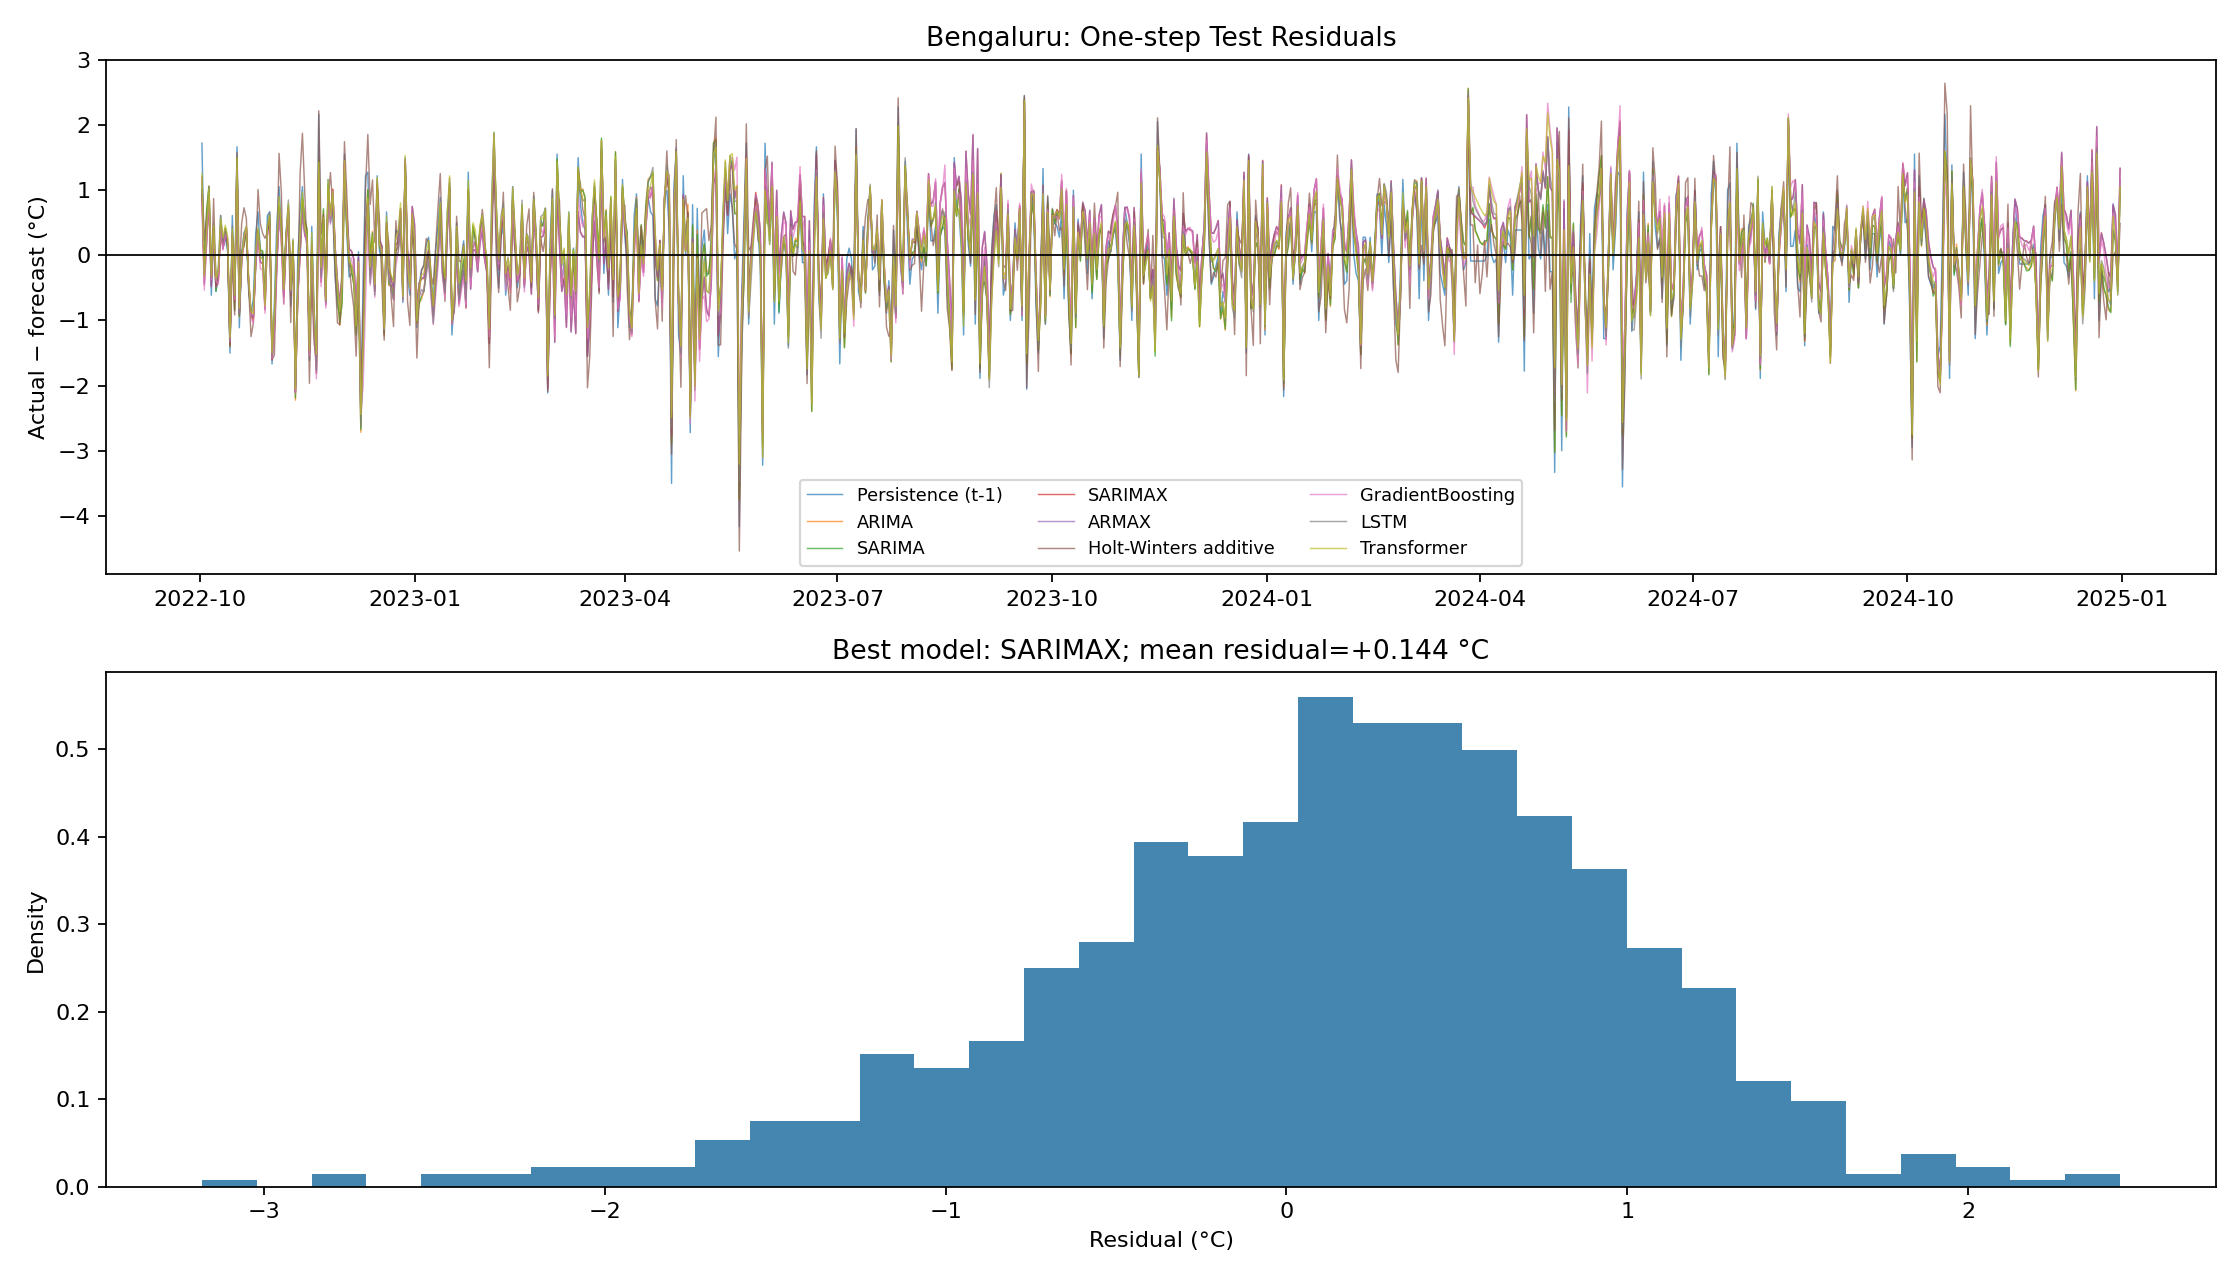

In [16]:
display(Image(filename=str(ROOT / "figures" / "rubric_extension" / "bengaluru" / "residual_diagnostics.png")))

## 9. Research conclusion

Across the common 2022-10-02 to 2024-12-31 one-step holdout, the city with the lowest selected-model RMSE is the easiest in absolute error terms, and the city with the highest RMSE is the hardest. The leading family differs by city; therefore, no single family should be claimed as universally best. The cross-city family table uses equal-weight station averages, while each city's skill percentage compares with its own persistence forecast.

The multi-horizon Transformer comparison is a separate direct-forecast experiment from the one-step ARIMA-family model-selection results. Residual dependence, non-normality, single-station coverage, and the one temporal holdout limit how broadly to generalize these findings.

In [17]:
ranked = extension["cities_ranked_by_best_model_rmse"]
print(f"Lowest RMSE: {ranked[0]['city']} ({ranked[0]['best_rmse']:.3f} ?C; {ranked[0]['best_model']})")
print(f"Highest RMSE: {ranked[-1]['city']} ({ranked[-1]['best_rmse']:.3f} ?C; {ranked[-1]['best_model']})")
print("Best-model counts:")
display(pd.Series([row["best_model"] for row in ranked]).value_counts().rename_axis("Family/model").to_frame("Cities"))
print("Transformer mean-horizon skill range across cities:",
      f"{min(r['transformer_horizon_skill_pct'] for r in base['cities_ranked_by_best_one_step_rmse']):.1f}% to",
      f"{max(r['transformer_horizon_skill_pct'] for r in base['cities_ranked_by_best_one_step_rmse']):.1f}%")

Lowest RMSE: Bengaluru (0.826 ?C; SARIMAX)
Highest RMSE: Delhi (1.338 ?C; SARIMAX)
Best-model counts:


,Cities
Family/model,
SARIMAX,3
RandomForest,2
ARMAX,2
GradientBoosting,1


Transformer mean-horizon skill range across cities: 11.8% to 30.6%


## 10. Individual contribution (5 marks)

Replace the placeholders with the actual team members and work completed. Do not infer ownership from Git history or notebook cells.

In [18]:
contributions = pd.DataFrame([
    {"Member": "[Name]", "Contribution": "[Work performed]", "Evidence": "[File, analysis, or presentation section]"},
    {"Member": "[Name]", "Contribution": "[Work performed]", "Evidence": "[File, analysis, or presentation section]"},
    {"Member": "[Name]", "Contribution": "[Work performed]", "Evidence": "[File, analysis, or presentation section]"},
])
display(contributions)

,Member,Contribution,Evidence
0,[Name],[Work performed],"[File, analysis, or presentation section]"
1,[Name],[Work performed],"[File, analysis, or presentation section]"
2,[Name],[Work performed],"[File, analysis, or presentation section]"


## 11. Rubric checklist

### Original case-study analysis (10 marks)

| Component | Marks | Where addressed |
|---|---:|---|
| Research question | 1 | Section 1 |
| Dataset understanding | 1 | Section 2 |
| Time-series visualization | 1 | Section 3 |
| Trend and seasonality | 2 | Section 4 |
| Stationarity | 2 | Section 4 |
| ACF/PACF | 2 | Sections 4 and 6 |
| Initial findings/hypothesis | 1 | Sections 1 and 9 |

### Remaining forecasting rubric (25 marks)

| Component | Marks | Where addressed |
|---|---:|---|
| ARIMA/SARIMA/ARMAX/SARIMAX, order selection | 3 | Section 6; ADF/KPSS and AIC/BIC candidate tables |
| Holt-Winters | 3 | Sections 7 and 9; additive and damped variants |
| ML/DL models | 3 | Sections 5 and 7 |
| Baseline forecasts | 2 | Section 5 |
| Forecast accuracy | 2 | Sections 5 and 7 |
| Model comparison | 2 | Sections 7 and 8; family rankings and paired tests |
| Residual analysis | 3 | Section 8 |
| Research conclusion | 2 | Section 9 |
| Individual contribution | 5 | Section 10; complete with actual team contributions |
| **Total remaining** | **25** | |

## Data and reproducibility

The cleaned station files are in `data/processed/`; raw NOAA yearly files are in `data/raw/`. The base city pipeline is `src/run_all_cities.py`, and the remaining model/order-selection pipeline is `src/rubric_extension.py`. Running the latter from a clean checkout refits the candidate models and can take a long time; this notebook itself reads the saved results and figures. NOAA sources: [GSOD archive](https://www.ncei.noaa.gov/data/global-summary-of-the-day/access/) and [station history](https://www.ncei.noaa.gov/pub/data/noaa/isd-history.csv).
